# Student Performance Analysis and Prediction System
AIML with Python, Minor Project

The idea here is simple. Take real student data and use it to predict a student's
final exam grade, and while doing that, work out which things actually affect the
result (study time, attendance, earlier grades and so on).

I followed the same steps we did in the sessions: load the data, clean it, look
at it with stats and charts, split into train and test, train a Linear Regression
model, check how good it is, then cross-validate and tune it. A pass/fail
classifier is at the end.

**Dataset:** UCI Student Performance dataset (Cortez & Silva, 2008). It is real
data from two Portuguese secondary schools, 395 students, 33 columns. The final
grade `G3` is on a 0 to 20 scale (10 is the pass mark). Source:
https://archive.ics.uci.edu/dataset/320/student+performance (CC BY 4.0).

How the columns line up with the project brief:
- **study hours** to `studytime` (weekly study time, 1 = under 2h up to 4 = over 10h)
- **attendance** to `absences` (number of school absences; more absences means worse attendance)
- **previous exam marks** to `G1` and `G2` (first and second period grades)
- **final marks** to `G3` (the target)

Tools: Python, NumPy, Pandas, Matplotlib, Seaborn, Scikit-learn. Runs in Jupyter
or Google Colab.


## 1. Importing the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Loading and looking at the data

The file is the Math course data (`student-mat.csv`). Let me load it and see what
I am working with before touching anything.

In [2]:
df = pd.read_csv("student-mat.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

In [4]:
# how many missing values, and how many duplicate rows?
print("Missing values in each column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values in each column:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Duplicate rows: 0


This is real, well-maintained data, so it turns out there are no missing
values and no duplicate rows. That is good, but I still run the checks and keep
the handling code below, because with most real datasets you cannot assume that.

## 3. Picking the columns and making a few new ones

The dataset has 33 columns, which is more than I need. I keep the ones that match
the project (study time, attendance, earlier grades) plus a few useful
background columns:

- **Numeric:** `studytime`, `failures` (past class failures), `absences`, `G1`, `G2`.
- **Categorical:** `sex`, `address` (urban/rural), `internet`, `higher` (wants
  higher education), `schoolsup` (extra school support). These are text, so I
  one-hot encode them into 0/1 columns with `pd.get_dummies`.
- **Target:** `G3`, the final grade.

I also add two helper columns: a readable `study_band` from `studytime` for the
grouped charts, and a `pass_fail` label (pass if `G3 >= 10`, the Portuguese pass
mark).

In [5]:
df = df.drop_duplicates().reset_index(drop=True)

num_features = ["studytime", "failures", "absences", "G1", "G2"]
cat_features = ["sex", "address", "internet", "higher", "schoolsup"]
target = "G3"
PASS_MARK = 10

data = df[num_features + cat_features + [target]].copy()

# one-hot encode the text columns
data = pd.get_dummies(data, columns=cat_features, drop_first=True)

# helper columns
band_labels = {1: "<2 hrs", 2: "2-5 hrs", 3: "5-10 hrs", 4: ">10 hrs"}
df["study_band"] = df["studytime"].map(band_labels)
df["pass_fail"] = (df[target] >= PASS_MARK).astype(int)

data.head()

,studytime,failures,absences,G1,G2,G3,sex_M,address_U,internet_yes,higher_yes,schoolsup_yes
0,2,0,6,5,6,6,False,True,False,True,True
1,2,0,4,5,5,6,False,True,True,True,False
2,2,3,10,7,8,10,False,True,True,True,True
3,3,0,2,15,14,15,False,True,True,True,False
4,2,0,4,6,10,10,False,True,False,True,False


## 4. Descriptive statistics

Mean, median and standard deviation for the numeric columns, then the full
`describe()` table.

In [6]:
stat_cols = num_features + [target]
print("Mean:\n", df[stat_cols].mean().round(2))
print("\nMedian:\n", df[stat_cols].median().round(2))
print("\nStandard deviation:\n", df[stat_cols].std().round(2))

Mean:
 studytime     2.04
failures      0.33
absences      5.71
G1           10.91
G2           10.71
G3           10.42
dtype: float64

Median:
 studytime     2.0
failures      0.0
absences      4.0
G1           11.0
G2           11.0
G3           11.0
dtype: float64

Standard deviation:
 studytime    0.84
failures     0.74
absences     8.00
G1           3.32
G2           3.76
G3           4.58
dtype: float64


In [7]:
df[stat_cols].describe().round(2)

,studytime,failures,absences,G1,G2,G3
count,395.00,395.00,395.00,395.00,395.00,395.00
mean,2.04,0.33,5.71,10.91,10.71,10.42
std,0.84,0.74,8.00,3.32,3.76,4.58
min,1.00,0.00,0.00,3.00,0.00,0.00
25%,1.00,0.00,0.00,8.00,9.00,8.00
50%,2.00,0.00,4.00,11.00,11.00,11.00
75%,2.00,0.00,8.00,13.00,13.00,14.00
max,4.00,3.00,75.00,19.00,19.00,20.00


## 5. Visualising the data

The five charts the project asks for: a bar chart, a histogram, scatter plots, a
box plot and a correlation heatmap.

### 5.1 Bar chart: average final grade by weekly study time

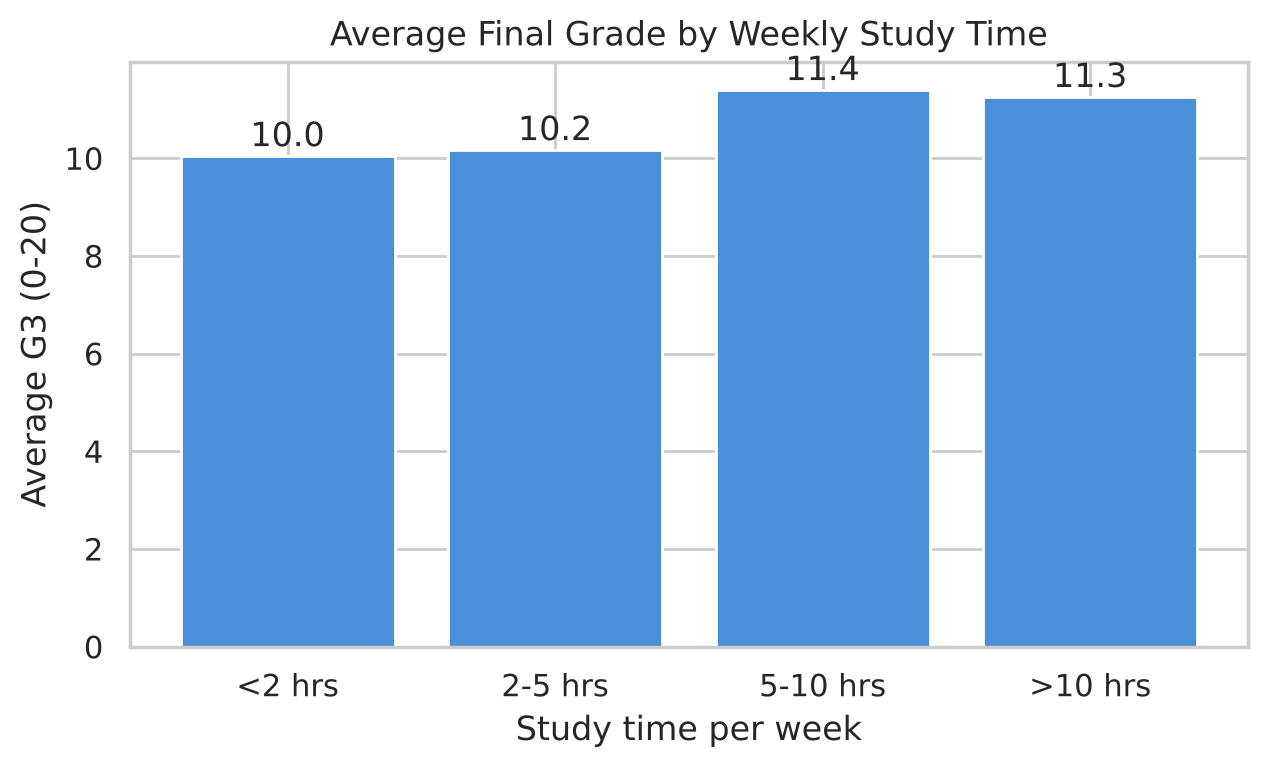

In [8]:
order = ["<2 hrs", "2-5 hrs", "5-10 hrs", ">10 hrs"]
avg = df.groupby("study_band", observed=True)["G3"].mean().reindex(order)
plt.figure(figsize=(6.5, 4))
plt.bar(avg.index, avg.values, color="#4a90d9")
plt.title("Average Final Grade by Weekly Study Time")
plt.xlabel("Study time per week"); plt.ylabel("Average G3 (0-20)")
for i, v in enumerate(avg.values):
    plt.text(i, v + 0.2, f"{v:.1f}", ha="center")
plt.tight_layout()
plt.savefig("fig_bar.png", dpi=110, bbox_inches="tight")
plt.show()

The average grade goes up as weekly study time goes up, though the jump is smaller than you might expect. Study time helps, but it is clearly not the only thing.

### 5.2 Histogram: how the final grades are spread out

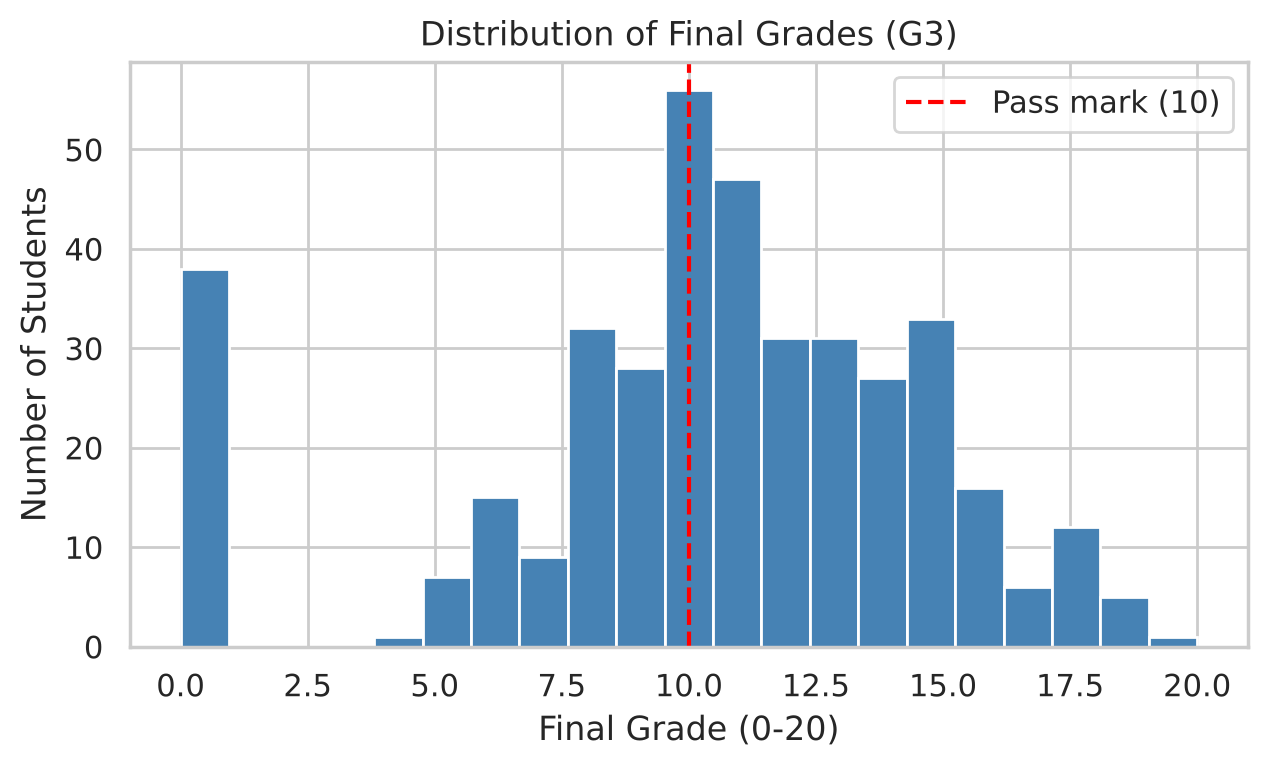

In [9]:
plt.figure(figsize=(6.5, 4))
plt.hist(df["G3"], bins=21, color="steelblue", edgecolor="white")
plt.axvline(PASS_MARK, color="red", linestyle="--", label=f"Pass mark ({PASS_MARK})")
plt.title("Distribution of Final Grades (G3)")
plt.xlabel("Final Grade (0-20)"); plt.ylabel("Number of Students")
plt.legend(); plt.tight_layout()
plt.savefig("fig_hist.png", dpi=110, bbox_inches="tight")
plt.show()

Most grades sit between 8 and 15. There is also a spike at 0, which is real: these are students who ended up with no final grade recorded, and I have left them in the data.

### 5.3 Scatter plots: study time, absences and G2 against the final grade

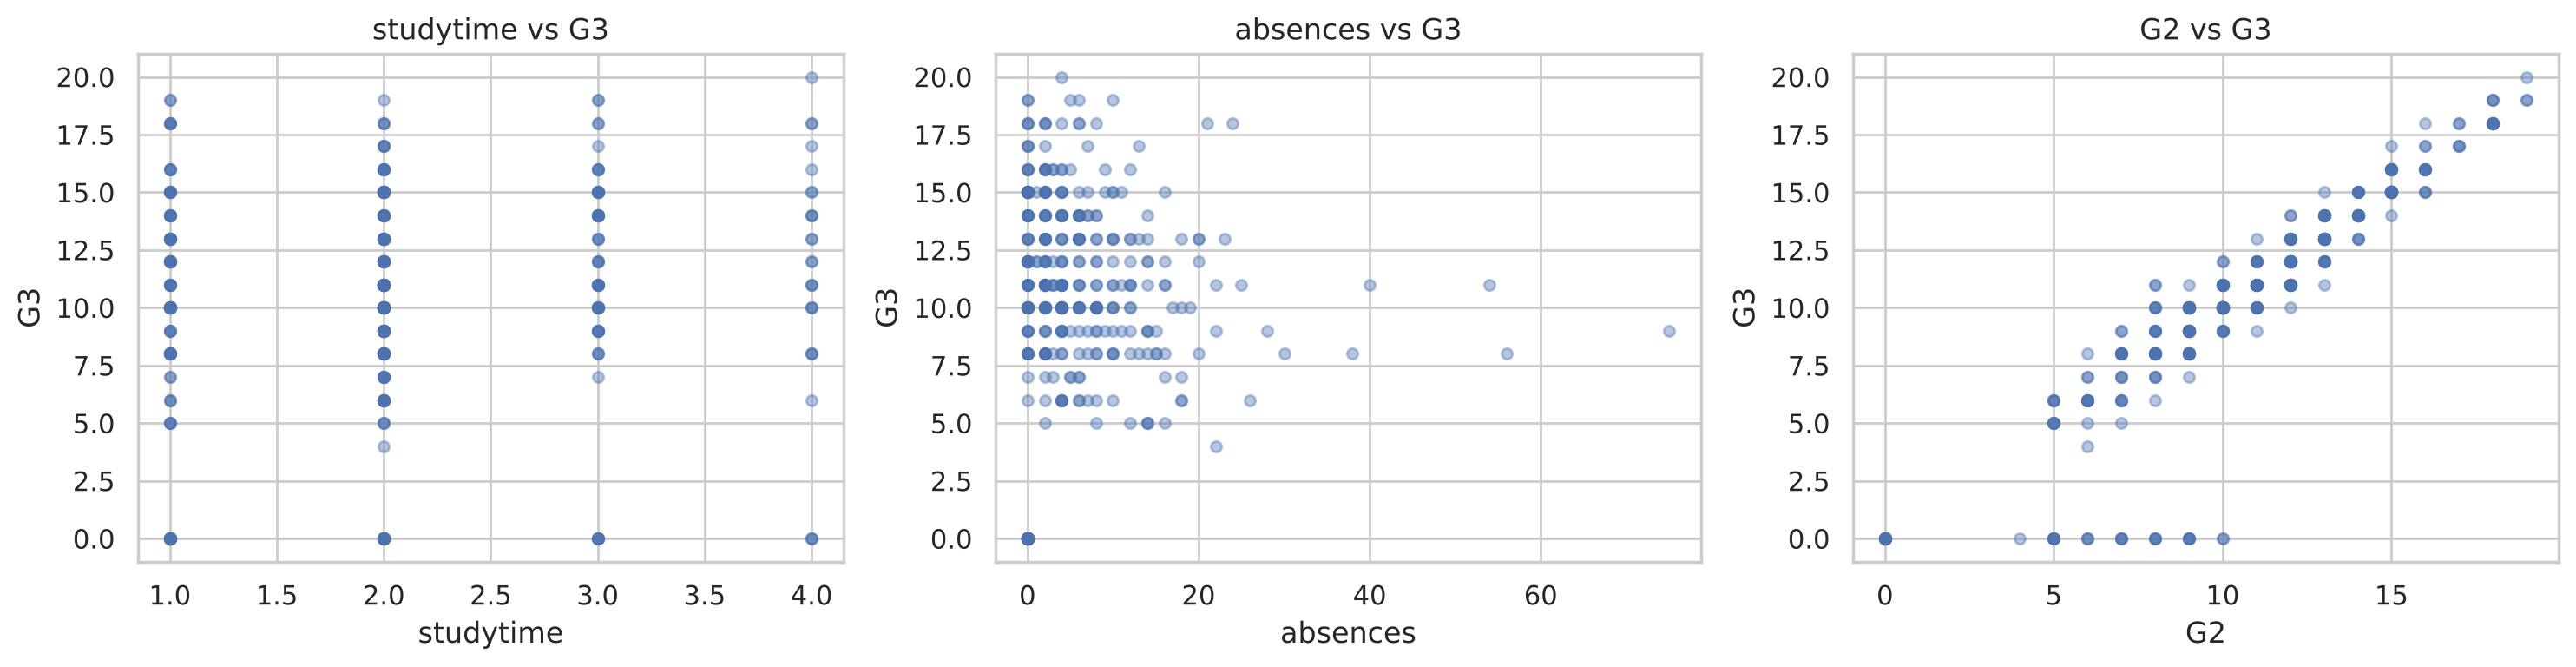

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["studytime", "absences", "G2"]):
    ax.scatter(df[col], df["G3"], alpha=0.4, s=20)
    ax.set_xlabel(col); ax.set_ylabel("G3")
    ax.set_title(f"{col} vs G3")
plt.tight_layout()
plt.savefig("fig_scatter.png", dpi=110, bbox_inches="tight")
plt.show()

The second period grade `G2` has a strong, clear positive link with the final grade. Study time trends up gently (it only takes four values, so it looks banded), and absences are scattered with a weak downward pull.

### 5.4 Box plot: final grade for each study time band

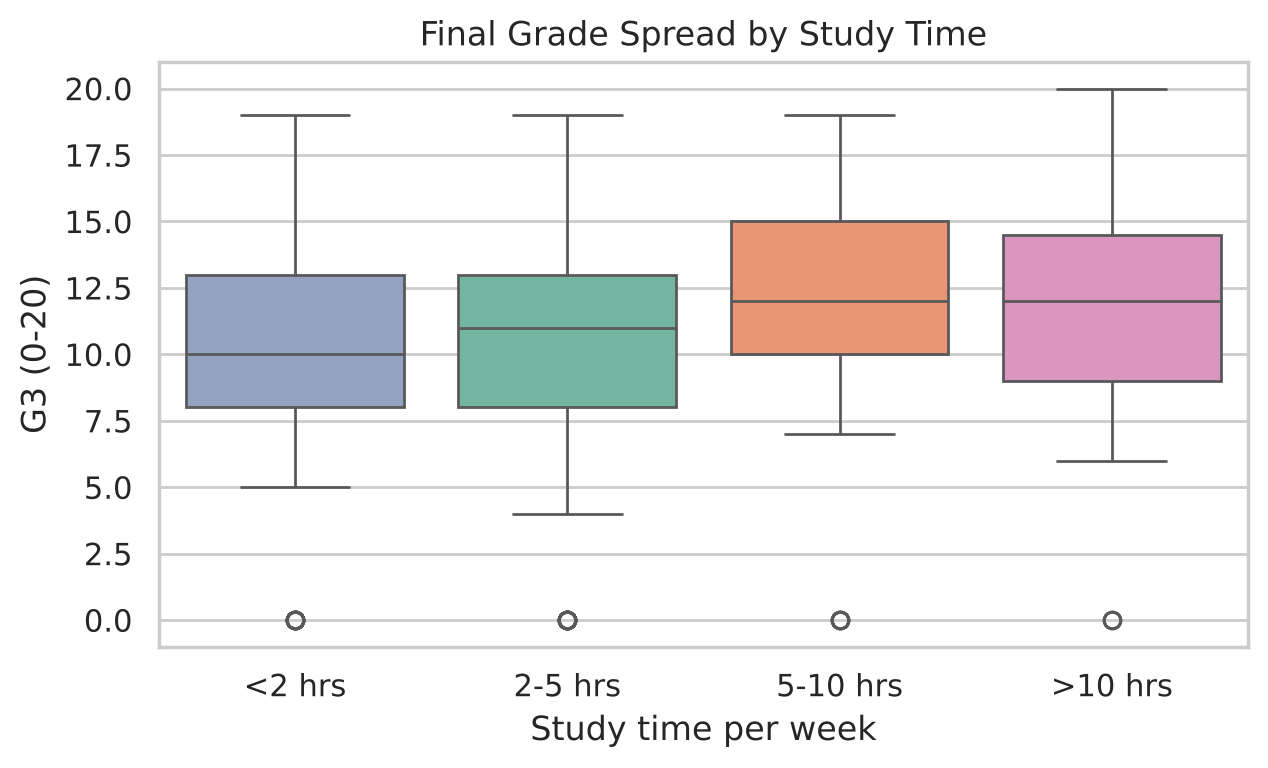

In [11]:
plt.figure(figsize=(6.5, 4))
sns.boxplot(data=df, x="study_band", y="G3", order=order,
            hue="study_band", palette="Set2", legend=False)
plt.title("Final Grade Spread by Study Time")
plt.xlabel("Study time per week"); plt.ylabel("G3 (0-20)")
plt.tight_layout()
plt.savefig("fig_box.png", dpi=110, bbox_inches="tight")
plt.show()

The medians drift upward with more study time, but the boxes overlap a lot, so study time on its own is not a strong separator of good and weak students.

### 5.5 Correlation heatmap

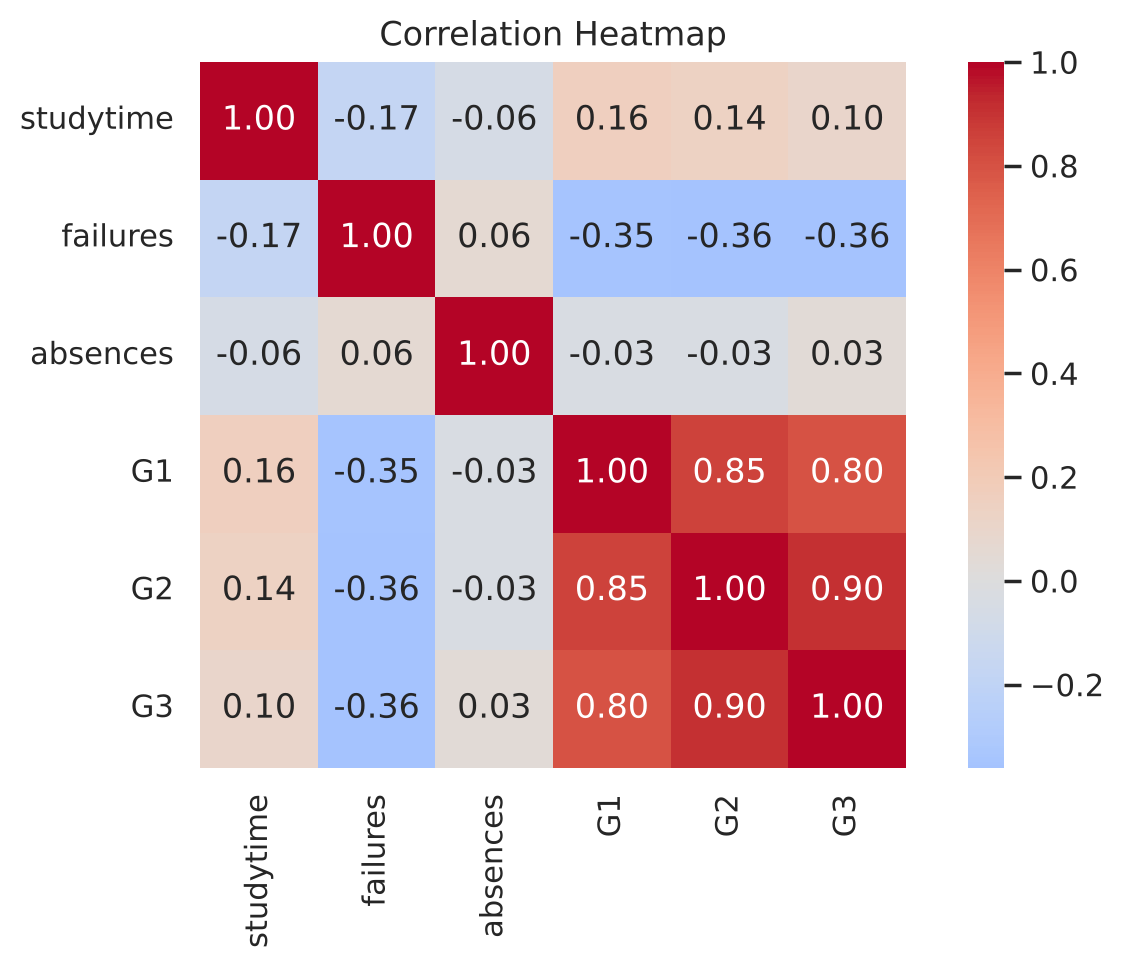

How strongly each column relates to G3:
G2           0.905
G1           0.801
studytime    0.098
absences     0.034
failures    -0.360
Name: G3, dtype: float64


In [12]:
plt.figure(figsize=(7, 5))
corr = df[["studytime", "failures", "absences", "G1", "G2", "G3"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("fig_heatmap.png", dpi=110, bbox_inches="tight")
plt.show()

print("How strongly each column relates to G3:")
print(corr["G3"].drop("G3").sort_values(ascending=False).round(3))

`G1` and `G2` are very strongly linked to the final grade, which makes sense: the two earlier exams are the best clue to the last one. `failures` pulls the grade down, and `absences` has only a weak effect here.

## 6. Features, target, and the train/test split

X is the input features and y is the final grade `G3`. I keep 80% for training
and 20% for testing. `random_state=42` just keeps the split the same every run.

In [13]:
feature_cols = [c for c in data.columns if c != target]
print("Features:", feature_cols)

X = data[feature_cols]
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), " Testing rows:", len(X_test))

Features: ['studytime', 'failures', 'absences', 'G1', 'G2', 'sex_M', 'address_U', 'internet_yes', 'higher_yes', 'schoolsup_yes']
Training rows: 316  Testing rows: 79


### 6.1 Filling missing values the safe way

This dataset has no missing values, but this is the correct way to handle them if
it did: work out the median from the training set only, then use that same value
to fill both sets. Doing it this way means the test data never leaks into
training.

In [14]:
train_medians = X_train.median()      # worked out from training rows only
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)
print("Missing values left:", int(X_train.isnull().sum().sum() + X_test.isnull().sum().sum()))

Missing values left: 0


## 7. Training the Linear Regression model

In [15]:
model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

## 8. Checking how good it is (MAE, MSE, RMSE, R2)

In [16]:
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("MAE :", round(mae, 2), "grade points")
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2), "grade points")
print("R2  :", round(r2, 3))

MAE : 1.41 grade points
MSE : 4.67
RMSE: 2.16 grade points
R2  : 0.772


Reading these: MAE is the average miss in grade points (out of 20), MSE
squares the errors so big misses hurt more, RMSE brings it back to grade points,
and R2 is how much of the variation in the final grade the model explains (1 is
perfect, 0 is no better than guessing the average).

### 8.1 Intercept and coefficients

Intercept: -2.26

Coefficient = how much the predicted grade changes per one-unit rise in the feature:
G2               0.96
schoolsup_yes    0.81
failures        -0.41
sex_M            0.37
higher_yes       0.27
internet_yes    -0.23
G1               0.18
absences         0.04
studytime       -0.03
address_U       -0.01
dtype: float64


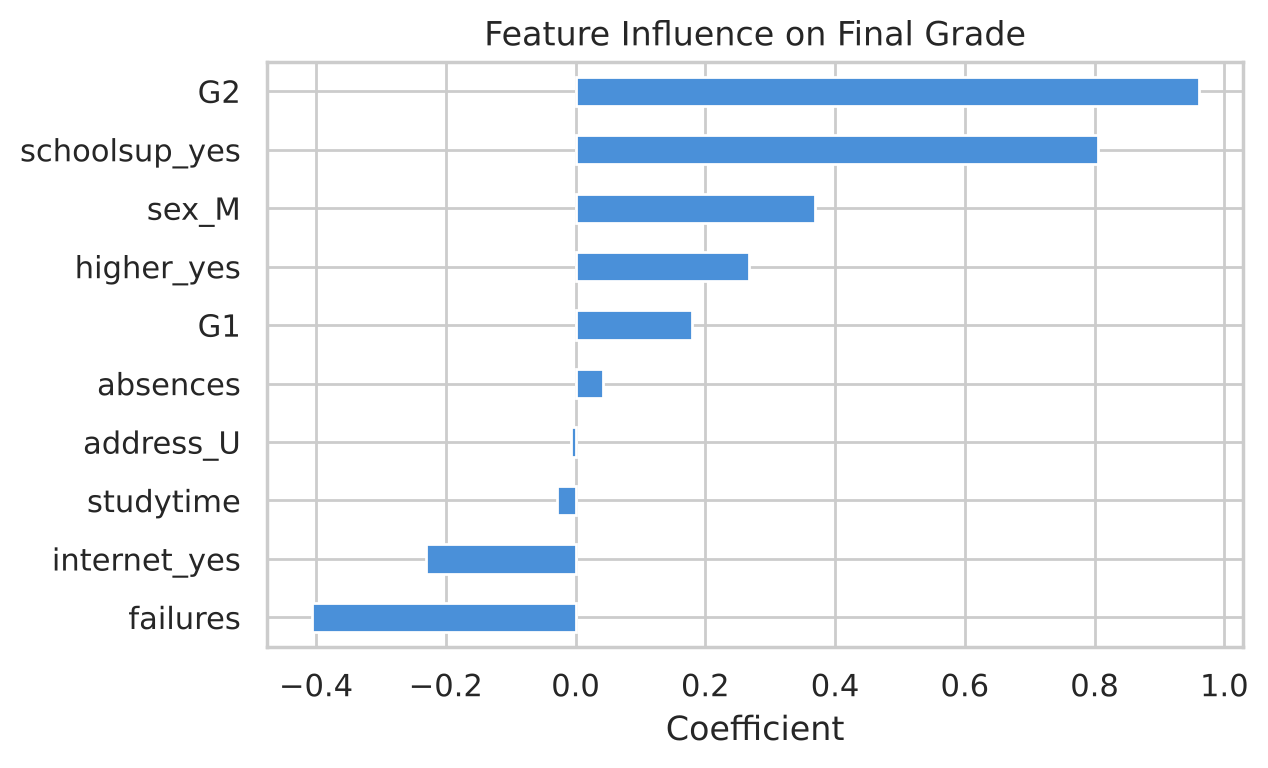

In [17]:
print("Intercept:", round(model.intercept_, 2))
coef = pd.Series(model.coef_, index=feature_cols).sort_values(key=abs, ascending=False)
print("\nCoefficient = how much the predicted grade changes per one-unit rise in the feature:")
print(coef.round(2))

plt.figure(figsize=(6.5, 4))
coef.sort_values().plot(kind="barh", color="#4a90d9")
plt.title("Feature Influence on Final Grade")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.savefig("fig_importance.png", dpi=110, bbox_inches="tight")
plt.show()

`G2` has by far the biggest coefficient, so the second period grade drives most of the prediction. Past failures push the grade down, as you would expect.

### 8.2 Actual vs predicted grades

In [18]:
results = pd.DataFrame({"actual_G3": y_test.values,
                        "predicted_G3": predictions.round(1)})
results["error"] = (results["actual_G3"] - results["predicted_G3"]).round(1)
print(results.head(15).to_string(index=False))

 actual_G3  predicted_G3  error
        10           6.6    3.4
        12          12.0    0.0
         5           3.4    1.6
        10           8.1    1.9
         9           8.2    0.8
        13          12.7    0.3
        18          18.9   -0.9
         6           7.2   -1.2
         0           6.8   -6.8
        14          12.9    1.1
        15          15.0    0.0
         7           5.9    1.1
        15          13.3    1.7
        10          11.6   -1.6
        14          14.6   -0.6


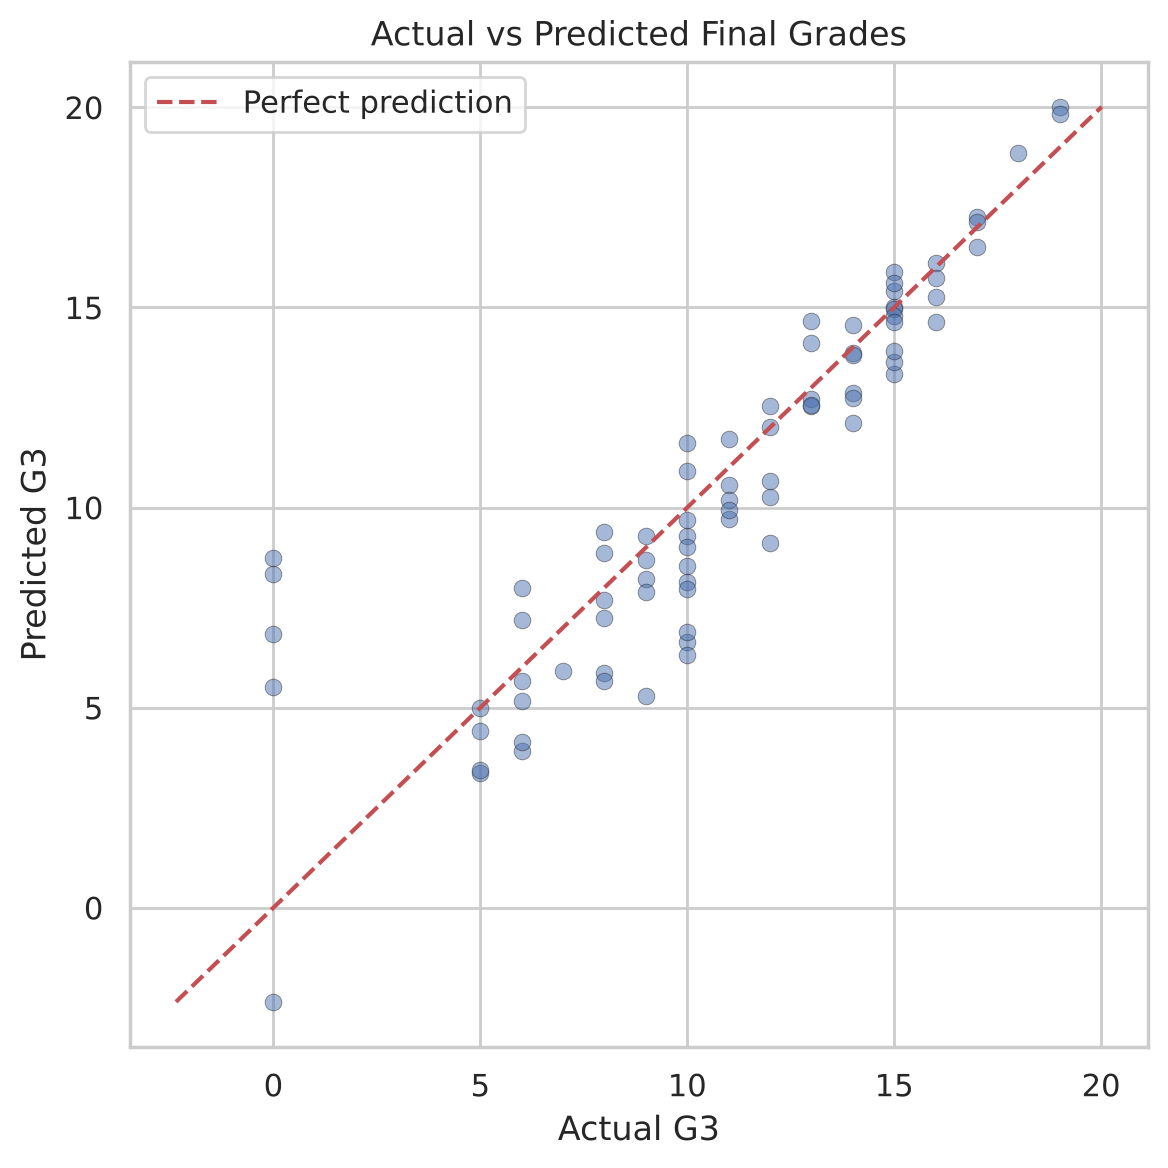

In [19]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predictions, alpha=0.5, edgecolor="k", linewidth=0.3)
line = [min(y_test.min(), predictions.min()), max(y_test.max(), predictions.max())]
plt.plot(line, line, "r--", label="Perfect prediction")
plt.title("Actual vs Predicted Final Grades")
plt.xlabel("Actual G3"); plt.ylabel("Predicted G3")
plt.legend(); plt.tight_layout()
plt.savefig("fig_actual_pred.png", dpi=110, bbox_inches="tight")
plt.show()

Most points sit close to the red line. The few that sit far below are mostly the real G3 = 0 students, which the model does not expect given their earlier grades.

## 9. Cross-validation

One split can be lucky or unlucky, so I run 5-fold cross-validation to check the
score holds up. Scikit-learn gives MAE back as a negative number (just its
convention), so I flip the sign.

In [20]:
cv_r2 = cross_val_score(model, X, y, cv=5, scoring="r2")
cv_mae = -cross_val_score(model, X, y, cv=5, scoring="neg_mean_absolute_error")

print("R2 for each fold:", np.round(cv_r2, 3))
print("Average R2 :", round(cv_r2.mean(), 3), " (spread +/-", round(cv_r2.std(), 3), ")")
print("Average MAE:", round(cv_mae.mean(), 2), "grade points")

R2 for each fold: [0.842 0.888 0.839 0.763 0.718]
Average R2 : 0.81  (spread +/- 0.061 )
Average MAE: 1.22 grade points


The R2 stays in a similar range across the folds, so the result is reasonably steady and not just down to one lucky split.

## 10. Hyperparameter tuning with GridSearchCV

Linear Regression has nothing to tune, so (like in the session) I run GridSearchCV
on a Decision Tree Regressor instead, over `max_depth` and `min_samples_split`
with K-Fold. This also gives me a second model to compare against.

In [21]:
param_grid = {"max_depth": [2, 4, 6], "min_samples_split": [2, 5, 10]}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

tree = DecisionTreeRegressor(random_state=42)
grid_search = GridSearchCV(tree, param_grid=param_grid, cv=cv,
                           scoring="neg_mean_squared_error", n_jobs=1)
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best tree CV RMSE:", round(np.sqrt(-grid_search.best_score_), 2), "grade points")

tree_pred = grid_search.predict(X_test)
print("Tuned tree test RMSE:", round(np.sqrt(mean_squared_error(y_test, tree_pred)), 2), "grade points")
print("Linear Regression test RMSE:", round(rmse, 2), "grade points  <- compare with this")

Best parameters: {'max_depth': 6, 'min_samples_split': 10}
Best tree CV RMSE: 1.86 grade points
Tuned tree test RMSE: 2.25 grade points
Linear Regression test RMSE: 2.16 grade points  <- compare with this


Putting both models on the same test set lets me actually pick the better one instead of just trusting the first one I trained.

## 11. Students who might need extra help

This is the useful part. I pull out the students whose *predicted* grade is below
the pass mark, so a teacher could step in before the final exam instead of after.

In [22]:
at_risk = results[results["predicted_G3"] < PASS_MARK].sort_values("predicted_G3")
print(f"{len(at_risk)} students are predicted to fall below the pass mark of {PASS_MARK}:")
print(at_risk.to_string(index=False))

39 students are predicted to fall below the pass mark of 10:
 actual_G3  predicted_G3  error
         0          -2.4    2.4
         5           3.4    1.6
         5           3.4    1.6
         6           3.9    2.1
         6           4.1    1.9
         5           4.4    0.6
         5           5.0    0.0
         6           5.2    0.8
         9           5.3    3.7
         0           5.5   -5.5
         8           5.7    2.3
         6           5.7    0.3
         8           5.9    2.1
         7           5.9    1.1
        10           6.3    3.7
        10           6.6    3.4
         0           6.8   -6.8
        10           6.9    3.1
         8           7.2    0.8
         6           7.2   -1.2
         8           7.7    0.3
         9           7.9    1.1
        10           8.0    2.0
         6           8.0   -2.0
        10           8.1    1.9
         9           8.2    0.8
         0           8.3   -8.3
        10           8.5    1.5
         9 

## 12. Optional part: predicting pass or fail

Here I switch from predicting the exact grade to just predicting pass or fail
(pass if `G3 >= 10`). Like in the classification session, I train four models and
compare them: Logistic Regression, KNN, Decision Tree and Random Forest. KNN and
Logistic Regression use scaled features (KNN works on distances, so scale
matters); the tree models do not need scaling.

In [23]:
# target becomes pass/fail, from the same split
yc_train = (y_train >= PASS_MARK).astype(int)
yc_test = (y_test >= PASS_MARK).astype(int)

# scaling, fitted on training rows only, for the distance-based models
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

preds = {}
m = LogisticRegression(max_iter=1000); m.fit(X_train_s, yc_train)
preds["Logistic Regression"] = m.predict(X_test_s)
m = KNeighborsClassifier(n_neighbors=3); m.fit(X_train_s, yc_train)
preds["KNN (k=3)"] = m.predict(X_test_s)
m = DecisionTreeClassifier(max_depth=3, random_state=42); m.fit(X_train, yc_train)
preds["Decision Tree"] = m.predict(X_test)
m = RandomForestClassifier(n_estimators=100, random_state=42); m.fit(X_train, yc_train)
preds["Random Forest"] = m.predict(X_test)

rows = {}
for name, p in preds.items():
    rows[name] = {"Accuracy": accuracy_score(yc_test, p),
                  "Precision": precision_score(yc_test, p),
                  "Recall": recall_score(yc_test, p),
                  "F1": f1_score(yc_test, p)}
comparison = pd.DataFrame(rows).T.round(3)
comparison

,Accuracy,Precision,Recall,F1
Logistic Regression,0.886,0.922,0.904,0.913
KNN (k=3),0.861,0.873,0.923,0.897
Decision Tree,0.911,0.979,0.885,0.929
Random Forest,0.899,0.958,0.885,0.920


Accuracy alone can be misleading when one class is bigger than the other, so I keep precision, recall and F1 next to it (the fraud example from the session).

### 12.1 Confusion matrix and classification report for the best model

Best model by F1: Decision Tree


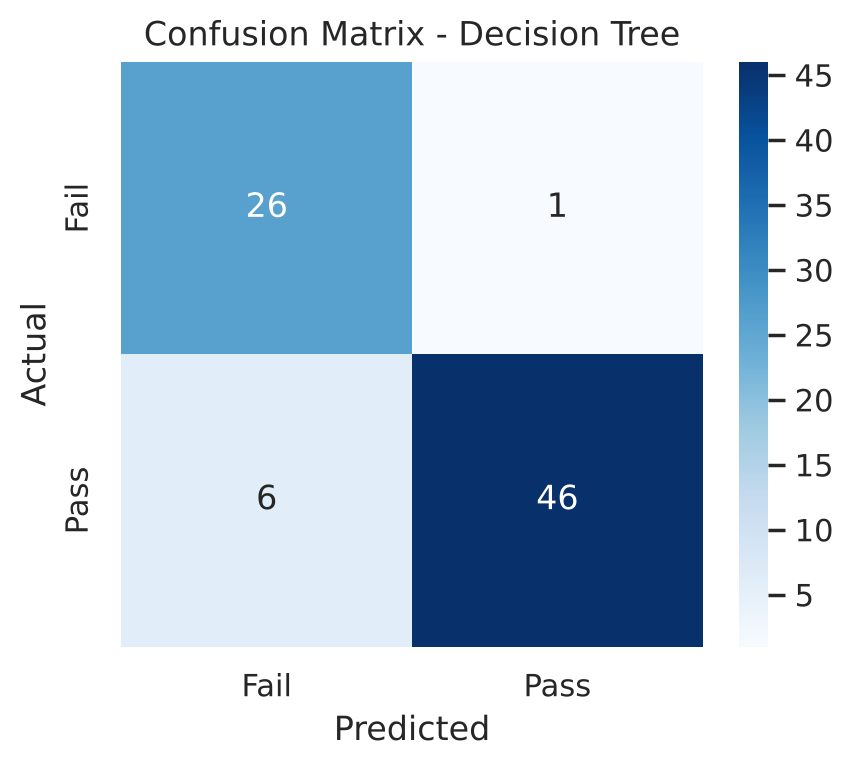

              precision    recall  f1-score   support

        Fail       0.81      0.96      0.88        27
        Pass       0.98      0.88      0.93        52

    accuracy                           0.91        79
   macro avg       0.90      0.92      0.91        79
weighted avg       0.92      0.91      0.91        79



In [24]:
best = comparison["F1"].idxmax()
print("Best model by F1:", best)

cm = confusion_matrix(yc_test, preds[best])
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"])
plt.title(f"Confusion Matrix - {best}")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("fig_confusion.png", dpi=110, bbox_inches="tight")
plt.show()

print(classification_report(yc_test, preds[best], target_names=["Fail", "Pass"]))

## 13. Conclusion

What I found:

- The earlier grades `G1` and `G2` are by far the strongest predictors of the
  final grade, followed by past failures. Study time and attendance matter, but
  less than the earlier results do.
- The Linear Regression model predicts the final grade within roughly a grade and
  a half on average, and cross-validation says that score is steady.
- The same model can point out students who are likely to fall below the pass
  mark, which is the genuinely useful part for a teacher.

Where it falls short:

- Using `G1` and `G2` makes the job easier. The dataset authors point out that
  predicting `G3` without them is harder but more useful, so a stronger version
  of this project would try that.
- The data is from two Portuguese schools in 2008, so the exact numbers will not
  carry over to other schools or systems.
- Linear Regression draws straight-line relationships, and a feature being linked
  to the grade does not mean it causes it.

What I would do next:

- Try predicting `G3` without `G1` and `G2` to see how much the behaviour columns
  alone can do.
- Try a few more models and compare them properly.
- Test the final model on the Portuguese-language file (`student-por.csv`) to see
  if it holds up on different students.

*(The cell below just saves the numbers to a file so the report can use them. It is not part of the analysis.)*

In [25]:
import json
metrics = {
    "rows": int(len(df)), "features": feature_cols,
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "mae": round(float(mae), 2), "mse": round(float(mse), 2),
    "rmse": round(float(rmse), 2), "r2": round(float(r2), 3),
    "cv_r2_mean": round(float(cv_r2.mean()), 3), "cv_r2_std": round(float(cv_r2.std()), 3),
    "cv_mae_mean": round(float(cv_mae.mean()), 2),
    "intercept": round(float(model.intercept_), 2),
    "coef": {k: round(float(v), 2) for k, v in coef.items()},
    "best_tree_params": grid_search.best_params_,
    "tree_test_rmse": round(float(np.sqrt(mean_squared_error(y_test, tree_pred))), 2),
    "n_at_risk": int(len(at_risk)),
    "classifier_table": comparison.to_dict(orient="index"),
    "best_classifier": best,
    "pass_mark": PASS_MARK,
}
with open("metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("Saved metrics.json")

Saved metrics.json
